# 2. What is predictable?

Before any model: which parts of a fantasy score repeat from week to week, which recent-form window
predicts best, and how much matchups and Vegas totals really move the needle.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fantasy.data import load_player_weeks, load_games
from fantasy.features import FEATURES, TARGET, build_features, model_sample, mingus_projection
from fantasy import plots as P

P.use_style()
pd.set_option("display.precision", 3)

In [2]:
df = pd.read_parquet("../data/features.parquet")
sample = model_sample(df)

## Volume repeats; touchdowns and efficiency mostly don't

**Split-half reliability:** for each player-season with 10+ games, average a stat over odd weeks and
over even weeks, then correlate the two halves across players. A stat that reflects a real skill or role
shows up in both halves (r near 1). One that's mostly luck doesn't (r near 0).

In [3]:
df["yards_per_target"] = df.receiving_yards / df.targets.replace(0, np.nan)
df["yards_per_carry"] = df.rushing_yards / df.carries.replace(0, np.nan)

STATS = {"targets": "Targets", "carries": "Carries", "opportunities": "Carries + targets",
         "receiving_yards": "Receiving yards", "rushing_yards": "Rushing yards",
         "touch_tds": "Touchdowns", "yards_per_target": "Yards per target",
         "yards_per_carry": "Yards per carry", "fantasy_points_ppr": "PPR points"}

def split_half(d, stat, min_games=10):
    d = d.assign(half=d.week % 2)
    n = d.groupby(["player_id", "season"]).size()
    halves = d.groupby(["player_id", "season", "half"])[stat].mean().unstack()
    halves = halves.loc[halves.index.intersection(n[n >= min_games].index)].dropna()
    return halves[0].corr(halves[1])

rel = pd.DataFrame({pos: {label: split_half(df[df.position == pos], s) for s, label in STATS.items()}
                    for pos in ["WR", "RB", "TE"]})
rel

,WR,RB,TE
Targets,0.902,0.808,0.894
Carries,0.793,0.914,0.970
Carries + targets,0.901,0.923,0.893
Receiving yards,0.839,0.700,0.791
Rushing yards,0.562,0.853,0.938
Touchdowns,0.436,0.577,0.337
Yards per target,0.171,0.090,0.181
Yards per carry,-0.082,0.159,0.125
PPR points,0.830,0.839,0.792


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/01_reliability.png')

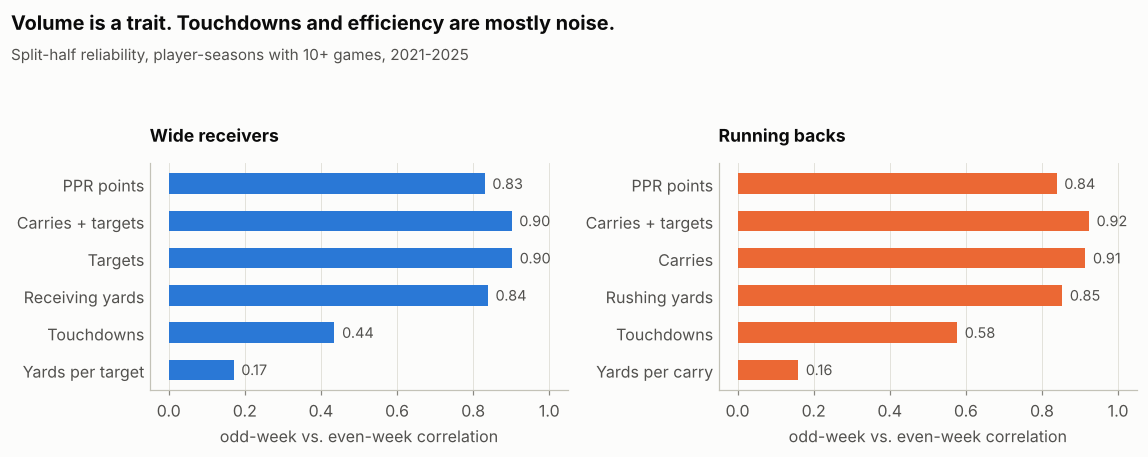

In [4]:
order = ["PPR points", "Carries + targets", "Targets", "Receiving yards", "Touchdowns", "Yards per target"]
wr = rel.loc[order, "WR"]
rb = rel.loc[["PPR points", "Carries + targets", "Carries", "Rushing yards", "Touchdowns", "Yards per carry"], "RB"]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharex=True)
for ax, series, color, pos in [(axes[0], wr, P.BLUE, "Wide receivers"), (axes[1], rb, P.ORANGE, "Running backs")]:
    y = np.arange(len(series))[::-1]
    ax.barh(y, series.values, height=0.55, color=color)
    for yi, v in zip(y, series.values):
        ax.text(v + 0.02, yi, f"{v:.2f}", va="center", color=P.INK_2, fontsize=9.5)
    ax.set_yticks(y, series.index)
    ax.set_xlim(-0.05, 1.05)
    ax.grid(axis="y", visible=False)
    ax.set_title(pos, fontsize=11.5)
    ax.tick_params(axis="y", length=0)
axes[0].set_xlabel("odd-week vs. even-week correlation")
axes[1].set_xlabel("odd-week vs. even-week correlation")
fig.suptitle("Volume is a trait. Touchdowns and efficiency are mostly noise.", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, 0.905, "Split-half reliability, player-seasons with 10+ games, 2021-2025", color=P.INK_2, fontsize=10, va="top")
fig.tight_layout(rect=(0, 0, 1, 0.86))
P.save(fig, "01_reliability")

A receiver's targets in odd weeks predict their targets in even weeks almost perfectly (r ≈ 0.9).
Touchdowns repeat far less (r ≈ 0.4), and yards per target is close to pure noise. **So when a
player's points run ahead of his volume, expect them to come back down.**

## Season average beats the hot hand

How well does each simple "recent form" number correlate with what the player scores next, depending
on how many games into the season we are?

In [5]:
cols = {"last_game": "Last game", "avg_last3": "Last 3 games", "avg_season": "Season to date",
        "prior_season_avg": "Last season"}
sample["games_bucket"] = pd.cut(sample.games_prior, [2, 4, 6, 8, 10, 12, 17], labels=["3-4", "5-6", "7-8", "9-10", "11-12", "13+"])
by_week = pd.DataFrame({label: sample.dropna(subset=[c]).groupby("games_bucket", observed=True)
                        .apply(lambda d: d[c].corr(d[TARGET])) for c, label in cols.items()})
by_week

,Last game,Last 3 games,Season to date,Last season
games_bucket,,,,
3-4,0.286,0.410,0.419,0.445
5-6,0.326,0.418,0.461,0.412
7-8,0.313,0.424,0.455,0.433
9-10,0.330,0.427,0.480,0.375
11-12,0.303,0.421,0.469,0.367
13+,0.317,0.392,0.463,0.353


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/02_recent_form.png')

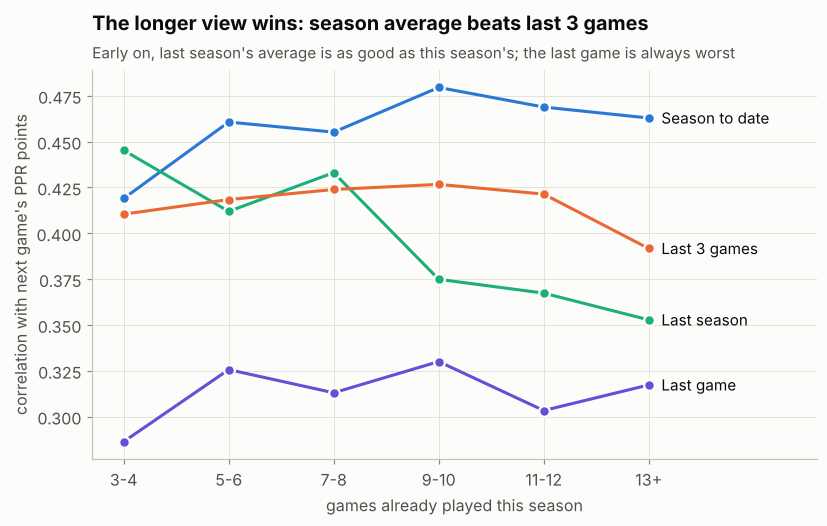

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = {"Season to date": P.BLUE, "Last season": P.AQUA, "Last 3 games": P.ORANGE, "Last game": P.VIOLET}
x = np.arange(len(by_week))
for label, color in colors.items():
    ax.plot(x, by_week[label], color=color, marker="o", markersize=7, markeredgecolor=P.SURFACE, markeredgewidth=1.5)
    ax.text(x[-1] + 0.12, by_week[label].iloc[-1], label, color=P.INK, va="center", fontsize=10)
ax.set_xticks(x, by_week.index)
ax.set_xlim(-0.3, len(x) - 1 + 1.6)
ax.set_xlabel("games already played this season")
ax.set_ylabel("correlation with next game's PPR points")
ax.set_title("The longer view wins: season average beats last 3 games", pad=26)
P.subtitle(ax, "Early on, last season's average is as good as this season's; the last game is always worst")
P.save(fig, "02_recent_form")

The single last game is the worst predictor at every point in the season, and the last three games are
consistently behind the full season average. Early on, **last season's** average is as good as this
season's three or four games. A model should use both.

## Matchups and Vegas totals: real, but smaller than people think

Group players by how generous this week's defense has been to their position (`def_factor`, in fifths), and
compare what they scored with their season average. If the matchup mattered a lot, the worst fifth of
matchups would score well below average and the best fifth well above.

In [7]:
def vs_expectation(d, col, q=5):
    bins = pd.qcut(d[col], q)
    out = d.groupby(bins, observed=True).agg(actual=(TARGET, "sum"), expected=("avg_season", "sum"),
                                             lo=(col, "min"), hi=(col, "max"), n=(TARGET, "size"))
    # Relative to a typical week: players in the sample score a bit under their season-to-date
    # average going forward (regression to the mean), so 1.0 = that typical ratio, not the raw average.
    out["ratio"] = (out.actual / out.expected) / (d[TARGET].sum() / d.avg_season.sum())
    return out.reset_index(drop=True)

sample["mingus_def"] = np.clip(sample.def_factor, 0.8, 1.2)
sample["mingus_vegas"] = np.clip(sample.implied_factor, 0.9, 1.1)
dvp = vs_expectation(sample, "def_factor")
dvp["mingus_assumes"] = sample.groupby(pd.qcut(sample.def_factor, 5), observed=True).mingus_def.mean().values
veg = vs_expectation(sample, "implied_total")
veg["mingus_assumes"] = sample.groupby(pd.qcut(sample.implied_total, 5), observed=True).mingus_vegas.mean().values
display(dvp.round(3)); display(veg.round(3))

,actual,expected,lo,hi,n,ratio,mingus_assumes
0,28600.50,30830.836,0.170,0.850,2622,0.952,0.810
1,29258.22,30919.655,0.850,0.949,2622,0.971,0.902
2,30294.34,31165.234,0.949,1.035,2621,0.997,0.993
3,30446.16,30403.353,1.035,1.141,2621,1.027,1.084
4,30784.44,29921.916,1.141,2.403,2621,1.055,1.189


,actual,expected,lo,hi,n,ratio,mingus_assumes
0,26171.18,27598.187,10.50,19.00,2729,0.973,0.900
1,30030.42,30817.548,19.25,21.50,2777,1.000,0.933
2,28139.10,29062.068,21.75,23.50,2488,0.993,1.020
3,31657.42,32217.235,23.75,25.75,2590,1.008,1.085
4,33385.54,33545.956,26.00,34.00,2523,1.021,1.100


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/03_matchup_vegas.png')

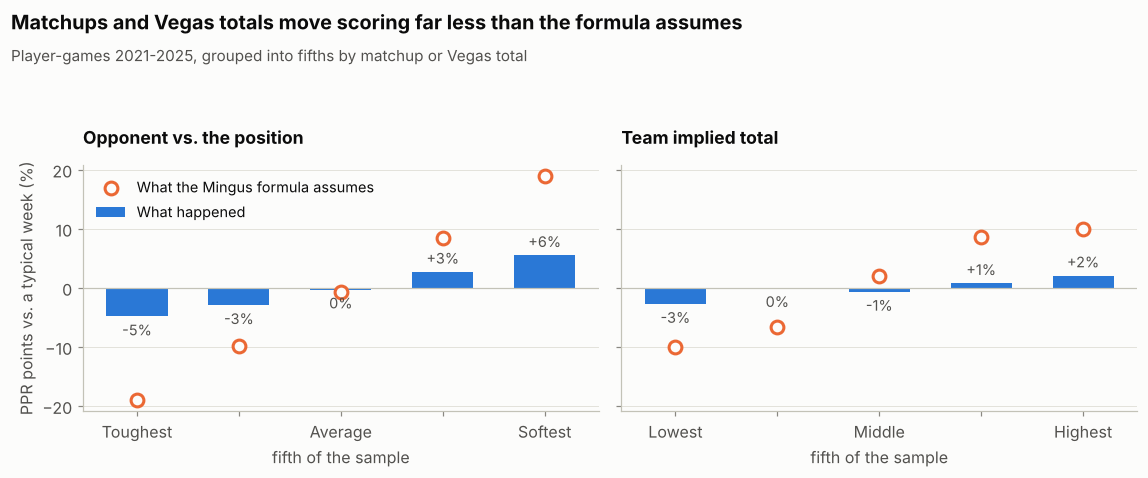

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), sharey=True)
panels = [(axes[0], dvp, "Opponent vs. the position", ["Toughest", "", "Average", "", "Softest"]),
          (axes[1], veg, "Team implied total", ["Lowest", "", "Middle", "", "Highest"])]
for ax, t, title, ticks in panels:
    x = np.arange(len(t))
    ax.bar(x, (t.ratio - 1) * 100, width=0.6, color=P.BLUE, label="What happened")
    ax.scatter(x, (t.mingus_assumes - 1) * 100, s=70, color=P.SURFACE, edgecolor=P.ORANGE, linewidth=2,
               zorder=3, label="What the Mingus formula assumes")
    for xi, v in zip(x, (t.ratio - 1) * 100):
        ax.text(xi, v + (0.8 if v >= 0 else -0.8), "0%" if round(v) == 0 else f"{v:+.0f}%", ha="center", va="bottom" if v >= 0 else "top",
                color=P.INK_2, fontsize=9.5)
    ax.axhline(0, color=P.GREY, linewidth=0.8)
    ax.set_xticks(x, ticks)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=11.5)
    ax.set_xlabel("fifth of the sample")
axes[0].set_ylabel("PPR points vs. a typical week (%)")
axes[0].legend(loc="upper left", fontsize=9.5)
fig.suptitle("Matchups and Vegas totals move scoring far less than the formula assumes", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, 0.905, "Player-games 2021-2025, grouped into fifths by matchup or Vegas total", color=P.INK_2, fontsize=10, va="top")
fig.tight_layout(rect=(0, 0, 1, 0.86))
P.save(fig, "03_matchup_vegas")

From the toughest fifth of matchups to the softest, scoring moves about 10% relative to a typical week.
The Mingus formula's factor assumes about 38% across the same groups. The Vegas implied total, once you already
know the player's average, moves things about 5% from lowest to highest (the formula assumes about 20%). Both effects
are real, just several times smaller than the formula's clamps allow. Defense-vs-position numbers are themselves noisy: a defense's "points allowed to WRs"
depends on which WRs it happened to face.